<a href="https://colab.research.google.com/github/maryamabdelkader/rnaseq-dge-airway/blob/main/RNAseq_DGE_airway.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RNA-seq Differential Expression Analysis (Airway dataset)

In this project I analyze RNA-seq data from human airway smooth muscle cells treated with **dexamethasone** (a corticosteroid used for asthma) compared to untreated cells.

The goal is to find which genes change after treatment and what biological pathways they belong to.

**Dataset:** GEO GSE52778 (Himes et al., 2014), 4 cell lines, each one treated and untreated = 8 samples.

**Steps:**
1. Load the data
2. Filter low count genes
3. Differential expression with PyDESeq2
4. PCA
5. Volcano plot and heatmap
6. Enrichment analysis

## 1. Install and import libraries

In [23]:
!pip install pydeseq2 gseapy mygene "pandas==2.2.3" -q

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

## 2. Load the data

In [25]:
counts_url = "https://raw.githubusercontent.com/bioconnector/workshops/master/data/airway_scaledcounts.csv"
metadata_url = "https://raw.githubusercontent.com/bioconnector/workshops/master/data/airway_metadata.csv"

counts = pd.read_csv(counts_url)
metadata = pd.read_csv(metadata_url)

In [26]:
counts.head()

,ensgene,SRR1039508,SRR1039509,SRR1039512,SRR1039513,SRR1039516,SRR1039517,SRR1039520,SRR1039521
0,ENSG00000000003,723.0,486.0,904.0,445.0,1170.0,1097.0,806.0,604.0
1,ENSG00000000005,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,ENSG00000000419,467.0,523.0,616.0,371.0,582.0,781.0,417.0,509.0
3,ENSG00000000457,347.0,258.0,364.0,237.0,318.0,447.0,330.0,324.0
4,ENSG00000000460,96.0,81.0,73.0,66.0,118.0,94.0,102.0,74.0


In [27]:
metadata

,id,dex,celltype,geo_id
0,SRR1039508,control,N61311,GSM1275862
1,SRR1039509,treated,N61311,GSM1275863
2,SRR1039512,control,N052611,GSM1275866
3,SRR1039513,treated,N052611,GSM1275867
4,SRR1039516,control,N080611,GSM1275870
5,SRR1039517,treated,N080611,GSM1275871
6,SRR1039520,control,N061011,GSM1275874
7,SRR1039521,treated,N061011,GSM1275875


The counts table has genes as rows and samples as columns.
PyDESeq2 needs the opposite (samples as rows), so I will transpose it.

In [28]:
counts = counts.set_index("ensgene")
counts = counts.T
counts = counts.round().astype(int)   # DESeq2 needs integer counts

metadata = metadata.set_index("id")
metadata = metadata[["dex", "celltype"]]

print(counts.shape)

(8, 38694)


In [29]:
# make sure samples are in the same order in both tables
print(counts.index.tolist() == metadata.index.tolist())

True


## 3. Filter genes with low counts

In [30]:
print("Genes before filtering:", counts.shape[1])

counts = counts.loc[:, counts.sum() >= 10]

print("Genes after filtering:", counts.shape[1])

Genes before filtering: 38694
Genes after filtering: 19271


## 4. Differential expression with PyDESeq2

I included `celltype` in the design because each cell line comes from a different donor.
This way the comparison between treated and control is done within the same cell line.

In [31]:
dds = DeseqDataSet(counts=counts, metadata=metadata, design="~celltype + dex")
dds.deseq2()

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.04 seconds.

Fitting dispersions...
... done in 24.14 seconds.

Fitting dispersion trend curve...
... done in 0.63 seconds.

/usr/local/lib/python3.13/dist-packages/pydeseq2/dds.py:548: UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.
  self.fit_dispersion_prior()
Fitting MAP dispersions...
... done in 28.31 seconds.

Fitting LFCs...
... done in 19.49 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.



In [32]:
stat_res = DeseqStats(dds, contrast=["dex", "treated", "control"])
stat_res.summary()

results = stat_res.results_df
results.head()

Running Wald tests...
... done in 10.72 seconds.



Log2 fold change & Wald test p-value: dex treated vs control
                    baseMean  log2FoldChange     lfcSE      stat    pvalue  \
ensgene                                                                      
ENSG00000000003   747.189148       -0.352976  0.124646 -2.831823  0.004628   
ENSG00000000419   520.134010        0.209332  0.137536  1.522016  0.128005   
ENSG00000000457   322.663544        0.028936  0.169063  0.171154  0.864103   
ENSG00000000460    87.682256       -0.132634  0.305147 -0.434656  0.663812   
ENSG00000000971  5760.147543        0.446466  0.093025  4.799431  0.000002   
...                      ...             ...       ...       ...       ...   
ENSG00000283091    58.877933       -0.190200  0.330277 -0.575881  0.564696   
ENSG00000283094  1881.014795       -0.347290  0.104601 -3.320126  0.000900   
ENSG00000283100   579.160373       -0.070216  0.135694 -0.517459  0.604836   
ENSG00000283101     7.068460        0.659164  0.925139  0.712502  0.476154   
ENS

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
ensgene,,,,,,
ENSG00000000003,747.189148,-0.352976,0.124646,-2.831823,0.004628,0.026560
ENSG00000000419,520.134010,0.209332,0.137536,1.522016,0.128005,0.334922
ENSG00000000457,322.663544,0.028936,0.169063,0.171154,0.864103,0.947669
ENSG00000000460,87.682256,-0.132634,0.305147,-0.434656,0.663812,0.851289
ENSG00000000971,5760.147543,0.446466,0.093025,4.799431,0.000002,0.000023


## 5. PCA

I use the normalized counts from DESeq2, then log transform them before PCA.

In [33]:
normalized = pd.DataFrame(dds.layers["normed_counts"], index=counts.index, columns=counts.columns)
log_counts = np.log2(normalized + 1)

pca = PCA(n_components=2)
pcs = pca.fit_transform(log_counts)

pca_df = pd.DataFrame(pcs, columns=["PC1", "PC2"], index=log_counts.index)
pca_df["dex"] = metadata["dex"]
pca_df["celltype"] = metadata["celltype"]

print(pca.explained_variance_ratio_)

[0.22648021 0.20740309]


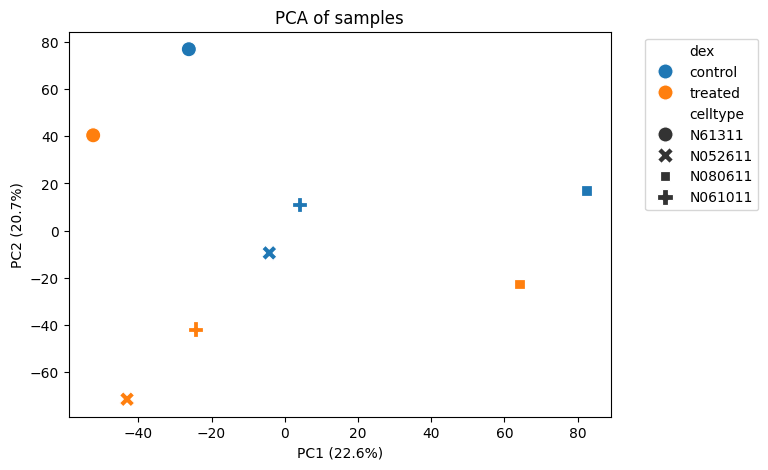

In [34]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="dex", style="celltype", s=120)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of samples")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.savefig("pca.png", dpi=300, bbox_inches="tight")
plt.show()

**Observation:** The samples don't separate by treatment on PC1. PC1 (22.6%) seems to be driven mostly by differences between cell lines, for example N080611 is far from the other samples.
But on PC2 (20.7%), the treated sample of each cell line is always lower than its control.
So the treatment effect is consistent, but the differences between donors are also large. This is why I added `celltype` to the DESeq2 design, so each treated sample is compared to its own control.

## 6. Add gene names

The results only have Ensembl IDs, so I use mygene to get the gene symbols.

In [35]:
import mygene

mg = mygene.MyGeneInfo()
gene_info = mg.querymany(results.index.tolist(), scopes="ensembl.gene",
                         fields="symbol", species="human", as_dataframe=True)

gene_info = gene_info[~gene_info.index.duplicated()]
results["symbol"] = gene_info["symbol"]

# some IDs have no symbol, so I keep the Ensembl ID for them
results["symbol"] = results["symbol"].fillna(results.index.to_series())
results.head()

INFO:biothings.client:querying 1-1000 ...
INFO:biothings.client:querying 1001-2000 ...
INFO:biothings.client:querying 2001-3000 ...
INFO:biothings.client:querying 3001-4000 ...
INFO:biothings.client:querying 4001-5000 ...
INFO:biothings.client:querying 5001-6000 ...
INFO:biothings.client:querying 6001-7000 ...
INFO:biothings.client:querying 7001-8000 ...
INFO:biothings.client:querying 8001-9000 ...
INFO:biothings.client:querying 9001-10000 ...
INFO:biothings.client:querying 10001-11000 ...
INFO:biothings.client:querying 11001-12000 ...
INFO:biothings.client:querying 12001-13000 ...
INFO:biothings.client:querying 13001-14000 ...
INFO:biothings.client:querying 14001-15000 ...
INFO:biothings.client:querying 15001-16000 ...
INFO:biothings.client:querying 16001-17000 ...
INFO:biothings.client:querying 17001-18000 ...
INFO:biothings.client:querying 18001-19000 ...
INFO:biothings.client:querying 19001-19271 ...
INFO:biothings.client:Finished.
INFO:biothings.client:Pass "returnall=True" to ret

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,symbol
ensgene,,,,,,,
ENSG00000000003,747.189148,-0.352976,0.124646,-2.831823,0.004628,0.026560,TSPAN6
ENSG00000000419,520.134010,0.209332,0.137536,1.522016,0.128005,0.334922,DPM1
ENSG00000000457,322.663544,0.028936,0.169063,0.171154,0.864103,0.947669,SCYL3
ENSG00000000460,87.682256,-0.132634,0.305147,-0.434656,0.663812,0.851289,FIRRM
ENSG00000000971,5760.147543,0.446466,0.093025,4.799431,0.000002,0.000023,CFH


## 7. Significant genes

I used padj < 0.05 and |log2FoldChange| > 1 as cutoffs.

In [36]:
results = results.dropna(subset=["padj"]).copy()
up = results[(results["padj"] < 0.05) & (results["log2FoldChange"] > 1)]
down = results[(results["padj"] < 0.05) & (results["log2FoldChange"] < -1)]

print("Upregulated genes:", len(up))
print("Downregulated genes:", len(down))

Upregulated genes: 431
Downregulated genes: 384


In [37]:
# top 10 genes by adjusted p-value
results.sort_values("padj").head(10)[["symbol", "log2FoldChange", "padj"]]

,symbol,log2FoldChange,padj
ensgene,,,
ENSG00000189221,MAOA,3.377427,5.730193e-157
ENSG00000101347,SAMHD1,3.757259,2.229446e-156
ENSG00000211445,GPX3,3.753779,3.870246e-149
ENSG00000120129,DUSP1,2.961563,4.786754e-143
ENSG00000109906,ZBTB16,5.953332,5.160620e-120
ENSG00000152583,SPARCL1,4.368724,1.376599e-108
ENSG00000196136,SERPINA3,3.160897,7.601026e-101
ENSG00000273259,ENSG00000273259,3.270506,2.197354e-98
ENSG00000154734,ADAMTS1,2.228676,1.446320e-95


Some of the top genes like **DUSP1** and **ZBTB16** are well known glucocorticoid target genes. Other known targets like **KLF15**, **PER1** and **CRISPLD2** are also in the top 30 (see the heatmap below), so the results make sense.

In [38]:
results.to_csv("deseq2_results.csv")

## 8. Volcano plot

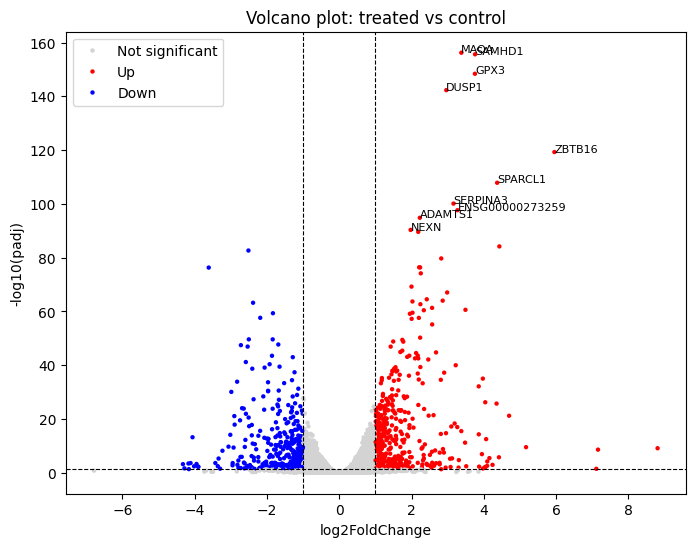

In [39]:
results["-log10(padj)"] = -np.log10(results["padj"])

# color genes based on significance
results["group"] = "Not significant"
results.loc[up.index, "group"] = "Up"
results.loc[down.index, "group"] = "Down"

colors = {"Up": "red", "Down": "blue", "Not significant": "lightgrey"}

plt.figure(figsize=(8, 6))
sns.scatterplot(data=results, x="log2FoldChange", y="-log10(padj)",
                hue="group", palette=colors, s=10, linewidth=0)

plt.axhline(-np.log10(0.05), color="black", linestyle="--", linewidth=0.8)
plt.axvline(1, color="black", linestyle="--", linewidth=0.8)
plt.axvline(-1, color="black", linestyle="--", linewidth=0.8)

# label top 10 genes
top10 = results.sort_values("padj").head(10)
for i, row in top10.iterrows():
    plt.text(row["log2FoldChange"], row["-log10(padj)"], row["symbol"], fontsize=8)

plt.legend(loc="upper left")
plt.title("Volcano plot: treated vs control")
plt.savefig("volcano_plot.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Heatmap of top 30 genes

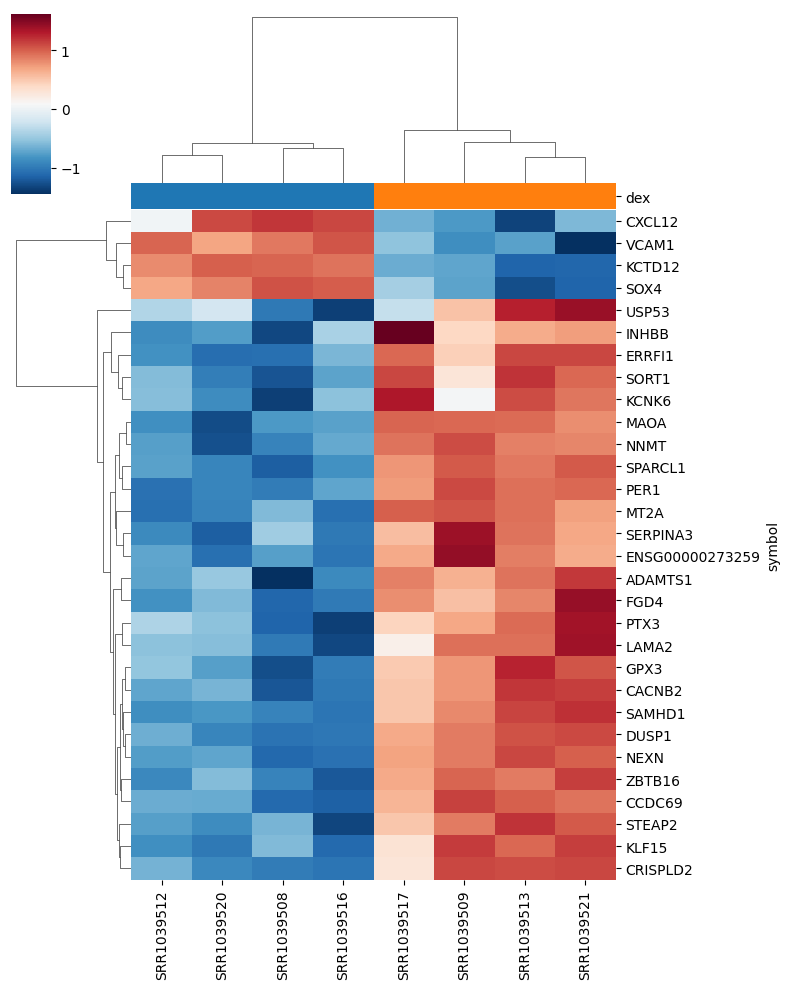

In [40]:
top30 = results.sort_values("padj").head(30)

heatmap_data = log_counts[top30.index].T
heatmap_data.index = top30["symbol"]

# color bar on top to show control vs treated
sample_colors = metadata["dex"].map({"control": "tab:blue", "treated": "tab:orange"})

sns.clustermap(heatmap_data, z_score=0, cmap="RdBu_r", figsize=(8, 10), col_colors=sample_colors)
plt.savefig("heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

**Observation:** The samples cluster perfectly into two groups, the 4 control samples and the 4 treated samples. So even with the differences between cell lines, these top genes clearly separate treated from untreated cells.
Most of the top 30 genes are upregulated after treatment. A few genes are downregulated, like **CXCL12** and **VCAM1**, which are involved in immune cell recruitment and inflammation.

## 10. Enrichment analysis

I used Enrichr (through gseapy) to see which biological processes are enriched in the upregulated and downregulated genes.

In [41]:
import gseapy as gp

up_genes = up["symbol"].dropna().tolist()
down_genes = down["symbol"].dropna().tolist()

enr_up = gp.enrichr(gene_list=up_genes, gene_sets="GO_Biological_Process_2023", organism="human")
enr_down = gp.enrichr(gene_list=down_genes, gene_sets="GO_Biological_Process_2023", organism="human")

In [42]:
enr_up.results.head(10)[["Term", "Adjusted P-value", "Genes"]]

,Term,Adjusted P-value,Genes
0,Positive Regulation Of Cell Differentiation (G...,0.000469,FBN2;SMARCD2;ZHX3;PKDCC;LAMA2;MMD;LMO3;ZBTB16;...
1,Negative Regulation Of Cell Motility (GO:2000146),0.001123,EPHA4;KANK1;MCTP1;CITED2;STC1;NEDD9;ADARB1;SPI...
2,Regulation Of Cell Migration (GO:0030334),0.001907,KANK1;CEMIP;MCTP1;CITED2;FAM107A;STC1;NEDD9;NE...
3,Response To Insulin (GO:0032868),0.022093,SORT1;LEP;ENPP1;IRS2;PPARG;INHBB;PIK3R1;SORBS1...
4,Negative Regulation Of Cell Migration (GO:0030...,0.022093,EPHA4;KANK1;MCTP1;CITED2;STC1;NEDD9;ADARB1;FOX...
5,Regulation Of Substrate Adhesion-Dependent Cel...,0.032537,KANK1;CARMIL1;PDPN;MYADM;RAC3;NEDD9;LIMS2
6,Regulation Of Glucose Import (GO:0046324),0.032537,LEP;PRKAG2;ENPP1;IRS2;PIK3R1;SORBS1
7,Cellular Response To Peptide Hormone Stimulus ...,0.032931,NR4A1;NR4A3;ENPP1;IRS2;PPARG;INHBB;PIK3R1;SORB...
8,Regulation Of Systemic Arterial Blood Pressure...,0.046240,OXTR;RASL10B;AGTR1;CORIN
9,Cellular Response To Zinc Ion (GO:0071294),0.046240,MT2A;MT1M;MT1X;MT1E


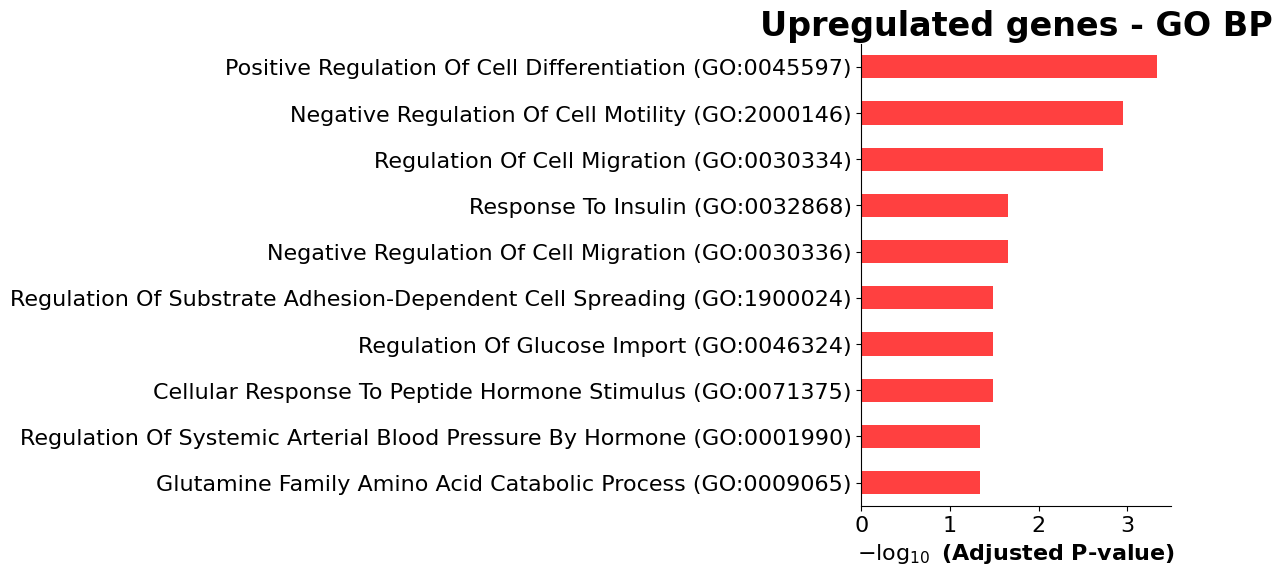

In [43]:
gp.barplot(enr_up.results, top_term=10, title="Upregulated genes - GO BP", color="red")
plt.savefig("enrichment_up.png", dpi=300, bbox_inches="tight")
plt.show()

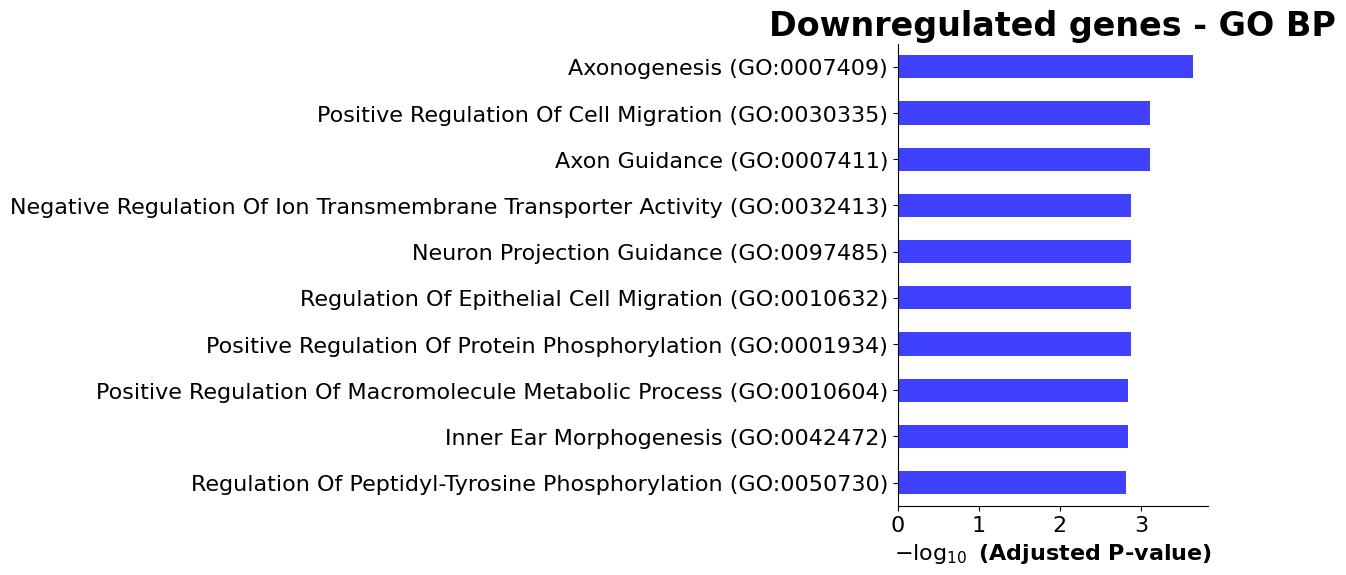

In [44]:
gp.barplot(enr_down.results, top_term=10, title="Downregulated genes - GO BP", color="blue")
plt.savefig("enrichment_down.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Conclusion

In this project I compared airway smooth muscle cells treated with dexamethasone to untreated cells from the same 4 cell lines.

**Main results:**
- After filtering, 19,271 genes were tested. Using padj < 0.05 and |log2FoldChange| > 1, I found **431 upregulated** and **384 downregulated** genes.
- The most significant genes were MAOA, SAMHD1, GPX3, DUSP1 and ZBTB16. Several known glucocorticoid targets (DUSP1, ZBTB16, KLF15, PER1, CRISPLD2) were among the top genes, which shows the analysis recovers the expected biology.
- CRISPLD2 was described in the original paper (Himes et al., 2014) as a new glucocorticoid responsive gene that may help reduce inflammation.
- Some genes related to inflammation were downregulated, like VCAM1 and CXCL12.
- The heatmap of the top 30 genes separates treated and control samples clearly, while the PCA showed that differences between cell lines are also large.

**Enrichment analysis:**
- Upregulated genes were enriched in negative regulation of cell motility and migration, and in insulin response and glucose import (genes like PPARG, IRS2 and PIK3R1). This fits with the known effects of glucocorticoids on cell metabolism.
- Downregulated genes were enriched in positive regulation of cell migration and in axon guidance terms. The axon guidance genes are probably related to cell movement in general, not to neurons specifically.
- Together, this suggests that dexamethasone may reduce the migration of airway smooth muscle cells, which could be related to less airway remodeling in asthma. This would need more experiments to confirm.

**Limitations:**
- Small sample size (only 4 cell lines), and large differences between donors.
- Only one dose and one time point (18 hours).
- Cells grown in culture may not behave the same as cells in the lungs of patients.
- The enrichment results depend on the cutoffs I used, and the adjusted p-values were not very strong.

**Next steps:**
- Run GSEA using all genes ranked by fold change instead of only significant genes.
- Compare these results with RNA-seq data from asthma patients.

**Reference:** Himes BE et al. (2014). RNA-Seq transcriptome profiling identifies CRISPLD2 as a glucocorticoid responsive gene that modulates cytokine function in airway smooth muscle cells. PLoS ONE 9(6): e99625.